In [1]:
import pandas as pd 

import numpy as np 

from sklearn.ensemble import GradientBoostingClassifier

from sklearn.model_selection import StratifiedKFold

from sklearn.metrics import f1_score, balanced_accuracy_score, matthews_corrcoef

import matplotlib.pyplot as plt

#https://scikit-learn.org/stable/modules/ensemble.html

In [2]:
data = pd.read_csv('Pv_loc_train.csv')
data = data.set_index('Sample')

target = data.loc[:, "Continent"]
target = target.replace({'SE_Asia':0, 'America':1, 'Asia':10, 'Africa':11}).astype(int) 
data_predictors = data.loc[:, data.columns != "Continent"]

In [3]:
test_data = pd.read_csv('Pv_loc_test.csv')
test_data = test_data.set_index('Sample')

y_test = test_data.loc[:, "Continent"]
y_test = y_test.replace({'SE_Asia':0, 'America':1, 'Asia':10, 'Africa':11}).astype(int)
x_test = test_data.loc[:, test_data.columns != "Continent"]

In [4]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.utils.class_weight import compute_sample_weight

def gb_test(features):
    gb = GradientBoostingClassifier(n_estimators=300, learning_rate=0.05,
                                    subsample=0.75, max_depth=2, random_state=42)
    gb.fit(data_predictors[features], target,
           sample_weight=compute_sample_weight("balanced", target))  

    y_pred = gb.predict(x_test[features])

    score = f1_score(y_test, y_pred, average="macro")
    matrix = confusion_matrix(y_test, y_pred, labels=sorted(target.unique()))

    return score, matrix

In [5]:
mrmr_barcode_scores = {}

mrmr_matrices = {}

barcode_lengths = [5, 10, 15, 20, 25, 30, 40, 50, 75, 100]

inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)

for length in barcode_lengths: 
    with open(f"MRMR_subsets/top_{length}_MRMR") as f:
        features = f.read().splitlines()
    score, matrix = gb_test(features)
    mrmr_matrices[length] = matrix
    mrmr_barcode_scores[length] = score

In [6]:
moremore = []
for length in barcode_lengths: 
    qual = mrmr_barcode_scores[length]
    moremore.append(qual)
    
moremore

[0.5333333333333333,
 0.5214285714285715,
 0.6375,
 0.6666666666666667,
 0.9142857142857143,
 0.9142857142857143,
 1.0,
 1.0,
 1.0,
 1.0]

In [7]:
gb_barcode_scores = {}

gb_matrices = {}

for length in barcode_lengths: 
    with open(f"GB_subsets/top_{length}_GB.txt") as f:
        features = f.read().splitlines()
    score, matrix = gb_test(features)
    gb_matrices[length] = matrix
    gb_barcode_scores[length] = score  

In [8]:
greatb = []
for length in barcode_lengths: 
    qual = gb_barcode_scores[length]
    greatb.append(qual)
    
greatb

[1.0, 0.9142857142857143, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

In [10]:
ga_barcode_scores = {}

ga_matrices = {}

for length in barcode_lengths: 
    with open(f"GA_subsets/top_{length}_GA.txt") as f:
        features = f.read().splitlines()
    score, matrix = gb_test(features)
    ga_matrices[length] = matrix
    ga_barcode_scores[length] = score  

In [11]:
goona = []
for length in barcode_lengths: 
    qual = ga_barcode_scores[length]
    goona.append(qual)
    
goona

[0.9142857142857143,
 0.7309253246753247,
 0.9333333333333333,
 0.7391304347826086,
 0.8333333333333333,
 0.6196808510638298,
 1.0,
 0.8391304347826086,
 0.9142857142857144,
 0.8125]

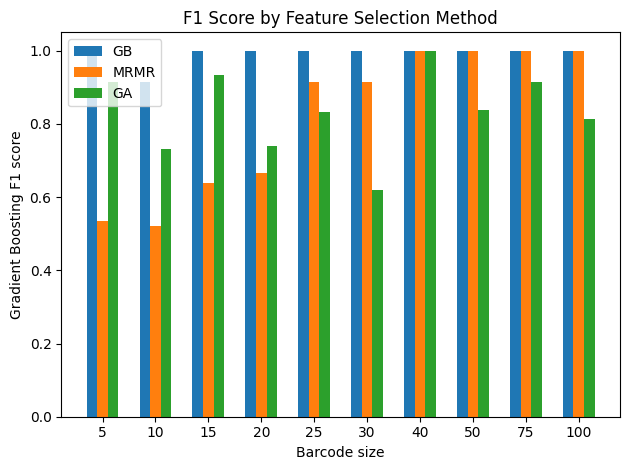

In [12]:
# Bar positions and width
x = np.arange(len(barcode_lengths))
width = 0.2

# Plot bars
plt.bar(x - width, gb_barcode_scores.values(), width, label='GB')
plt.bar(x, mrmr_barcode_scores.values(), width, label='MRMR')
plt.bar(x + width, ga_barcode_scores.values(), width, label='GA')

# Labels and formatting
plt.xlabel('Barcode size')
plt.ylabel('Gradient Boosting F1 score')
plt.title('F1 Score by Feature Selection Method')
plt.xticks(x, barcode_lengths)
plt.legend()
plt.tight_layout()

plt.show()

In [13]:
#Create confusion matrix 

labels = ['SE_Asia', 'America', 'Asia', 'Africa']

conf_table = pd.DataFrame(
    ga_matrices[10],
    index=labels,
    columns=labels
)

print(conf_table)

         SE_Asia  America  Asia  Africa
SE_Asia       23        0     0       0
America        2        4     0       1
Asia           0        0     2       1
Africa         0        0     1       2
